<a href="https://colab.research.google.com/github/LINIVR/AI-Research-Learning/blob/main/Telco%20Customer%20Churn%20Classification/01_Telco_Churn_Classification_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [148]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [149]:
df=pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [150]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [151]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [152]:
df.sample(7)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5926,1356-MKYSK,Male,0,No,No,6,Yes,No,DSL,Yes,No,Yes,Yes,Yes,Yes,Month-to-month,No,Credit card (automatic),78.65,483.3,No
618,5240-CAOYT,Female,0,No,No,57,Yes,Yes,Fiber optic,Yes,Yes,No,Yes,No,No,Month-to-month,Yes,Bank transfer (automatic),87.55,4884.85,No
2415,9898-KZQDZ,Female,1,Yes,Yes,40,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),94.55,3640.45,Yes
1783,8380-PEFPE,Male,0,No,Yes,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,71.65,71.65,Yes
302,8266-VBFQL,Male,0,No,No,4,Yes,No,Fiber optic,No,No,Yes,Yes,No,Yes,Month-to-month,Yes,Electronic check,90.40,356.65,No
3802,7698-YFGEZ,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.00,20,No
3149,3629-WEAAM,Female,0,No,No,8,Yes,No,DSL,No,No,Yes,Yes,No,Yes,Month-to-month,No,Mailed check,64.10,504.05,No


In [153]:
df.shape

(7043, 21)

In [154]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [156]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [157]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [158]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [159]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [160]:
df.duplicated().sum()

np.int64(0)

In [161]:
df['TotalCharges'].head(10)

,TotalCharges
0,29.85
1,1889.5
2,108.15
3,1840.75
4,151.65
5,820.5
6,1949.4
7,301.9
8,3046.05
9,3487.95


In [162]:
(df['TotalCharges']==' ').sum()

np.int64(11)

In [163]:
blank_index=df.loc[df['TotalCharges']==' '].index

In [164]:
print(blank_index)

Index([488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754], dtype='int64')


In [165]:
df.loc[df['TotalCharges']==' ']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [166]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [167]:
df.loc[df['TotalCharges']==' ',['customerID','tenure','MonthlyCharges','TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [168]:
df.loc[df['TotalCharges']==' ',['customerID','tenure','MonthlyCharges','TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [169]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'].str.strip(),errors='coerce')

In [170]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [171]:
df['TotalCharges']=df['TotalCharges'].fillna(0)

In [172]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [173]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [174]:
df.drop('customerID',axis=1,inplace=True)

In [175]:
numerical_features=[feature for feature in df.columns if df[feature].dtypes!='O']
print(numerical_features)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [176]:
continous_features=[feature for feature in numerical_features if df[feature].nunique()>10]
print(continous_features)

['tenure', 'MonthlyCharges', 'TotalCharges']


In [177]:
discrete_features=[feature for feature in numerical_features if df[feature].nunique()<10]
print(discrete_features)

['SeniorCitizen']


In [178]:
df['SeniorCitizen'].unique()

array([0, 1])

In [179]:
categorical_features=[feature for feature in df.columns if df[feature].dtypes=='O']
print(categorical_features)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [180]:
for feature in categorical_features:
  print(f"\n Feature:{feature}")
  print(df[feature].unique())


 Feature:gender
['Female' 'Male']

 Feature:Partner
['Yes' 'No']

 Feature:Dependents
['No' 'Yes']

 Feature:PhoneService
['No' 'Yes']

 Feature:MultipleLines
['No phone service' 'No' 'Yes']

 Feature:InternetService
['DSL' 'Fiber optic' 'No']

 Feature:OnlineSecurity
['No' 'Yes' 'No internet service']

 Feature:OnlineBackup
['Yes' 'No' 'No internet service']

 Feature:DeviceProtection
['No' 'Yes' 'No internet service']

 Feature:TechSupport
['No' 'Yes' 'No internet service']

 Feature:StreamingTV
['No' 'Yes' 'No internet service']

 Feature:StreamingMovies
['No' 'Yes' 'No internet service']

 Feature:Contract
['Month-to-month' 'One year' 'Two year']

 Feature:PaperlessBilling
['Yes' 'No']

 Feature:PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

 Feature:Churn
['No' 'Yes']


In [181]:
for feature in categorical_features:
  print(f"\n Feature:{feature}")
  print(df[feature].value_counts())


 Feature:gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

 Feature:Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

 Feature:Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

 Feature:PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

 Feature:MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

 Feature:InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

 Feature:OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

 Feature:OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

 Feature:DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet s

In [182]:
df['Churn'].value_counts(dropna=False)

,count
Churn,
No,5174
Yes,1869


In [183]:

df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [184]:
X=df.drop('Churn',axis=1)
y=df['Churn']

In [185]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [186]:
print("X_train shape:",X_train.shape)
print("X_test shape:",X_test.shape)
print("y_train shape:",y_train.shape)
print("y_test shape:",y_test.shape)

X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [187]:
print("\n Training Target distribution:", y_train.value_counts(normalize=True)*100)
print("\n Testing Target distribution:", y_test.value_counts(normalize=True)*100)



 Training Target distribution: Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

 Testing Target distribution: Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [188]:
categorical_features=X_train.select_dtypes(include=['object']).columns.tolist()

numerical_features=X_train.select_dtypes(include=['number']).columns.tolist()

In [189]:
print(categorical_features)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [190]:
print(numerical_features)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [191]:
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import OneHotEncoder,StandardScaler


In [192]:
preprocessor=ColumnTransformer(
    transformers=[
        ('categorical',OneHotEncoder(handle_unknown='ignore'),categorical_features),  #"If you encounter a category that wasn't seen during fitting,
                                                                                      #don't raise an error.
                                                                         #Instead, encode that unknown category as zeros across
                                                                # the encoded columns for that feature."
        ('numerical',StandardScaler(),numerical_features)
    ]
)

In [193]:
X_train_processed=preprocessor.fit_transform(X_train)
X_test_processed=preprocessor.transform(X_test)

In [194]:
print("Original training Shape",X_train.shape)
print("Processed training shape",X_train_processed.shape)
print("Original testiing Shape",X_test.shape)
print("Processed testingg shape",X_test_processed.shape)

Original training Shape (5634, 19)
Processed training shape (5634, 45)
Original testiing Shape (1409, 19)
Processed testingg shape (1409, 45)


# Train Different Classification Models

In [195]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import issparse


from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ( RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier,ExtraTreesClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from xgboost import XGBClassifier


from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score,RocCurveDisplay)

In [196]:
models ={
    "Logistic Regression":LogisticRegression(random_state=42,max_iter=1000),
    "Decision Tree Classifier":DecisionTreeClassifier(random_state=42),
    "Rndom Forest Classifier":RandomForestClassifier(random_state=42),
    "AdaBoost":AdaBoostClassifier(random_state=42),
    "Gradient Boosting":GradientBoostingClassifier(random_state=42),
     "Extra Trees":ExtraTreesClassifier(random_state=42),
    "XGBoost":XGBClassifier(random_state=42,eval_metric='logloss'),

    "SGD Classifier":SGDClassifier(random_state=42),

    "SVM":SVC(probability=True,random_state=42),
    "KNN":KNeighborsClassifier(),
    "Naive Bayes":GaussianNB(),



}

In [197]:
results={}


Model:Logistic Regression

Accuracy: 0.8055358410220014

 Classification Report :
               precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


 Confusion Matrix :
 [[926 109]
 [165 209]]

 ROC Score : 0.8421349040274871


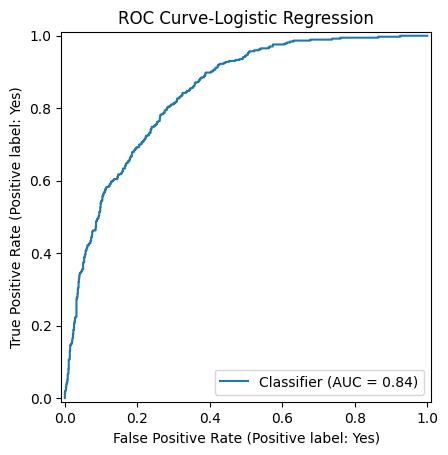


Model:Decision Tree Classifier

Accuracy: 0.7224982256919801

 Classification Report :
               precision    recall  f1-score   support

          No       0.82      0.80      0.81      1035
         Yes       0.48      0.50      0.49       374

    accuracy                           0.72      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.72      0.72      1409


 Confusion Matrix :
 [[832 203]
 [188 186]]

 ROC Score : 0.6503526311710455


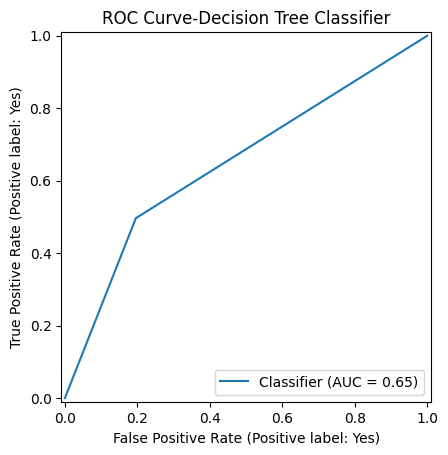


Model:Rndom Forest Classifier

Accuracy: 0.7877927608232789

 Classification Report :
               precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409


 Confusion Matrix :
 [[926 109]
 [190 184]]

 ROC Score : 0.8160854064946137


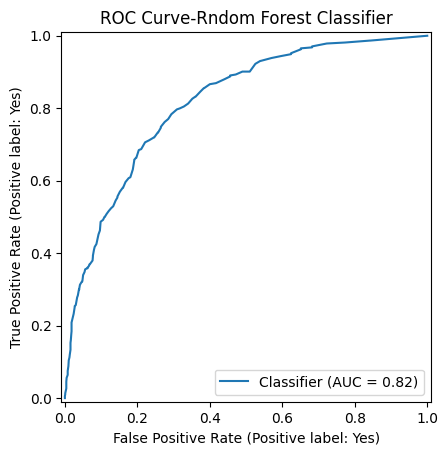


Model:AdaBoost

Accuracy: 0.8005677785663591

 Classification Report :
               precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409


 Confusion Matrix :
 [[920 115]
 [166 208]]

 ROC Score : 0.8431656720659277


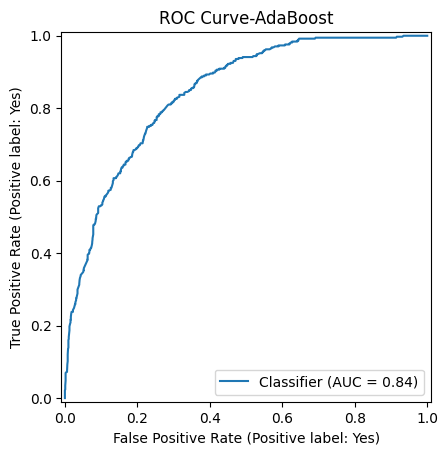


Model:Gradient Boosting

Accuracy: 0.8026969481902059

 Classification Report :
               precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409


 Confusion Matrix :
 [[938  97]
 [181 193]]

 ROC Score : 0.8434046345811052


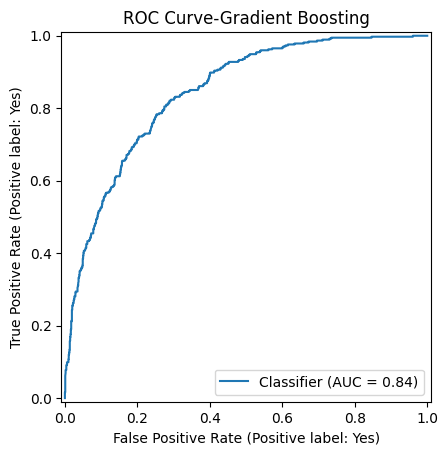


Model:Extra Trees

Accuracy: 0.765791341376863

 Classification Report :
               precision    recall  f1-score   support

          No       0.82      0.87      0.85      1035
         Yes       0.57      0.48      0.52       374

    accuracy                           0.77      1409
   macro avg       0.70      0.67      0.68      1409
weighted avg       0.75      0.77      0.76      1409


 Confusion Matrix :
 [[901 134]
 [196 178]]

 ROC Score : 0.7862680513575654


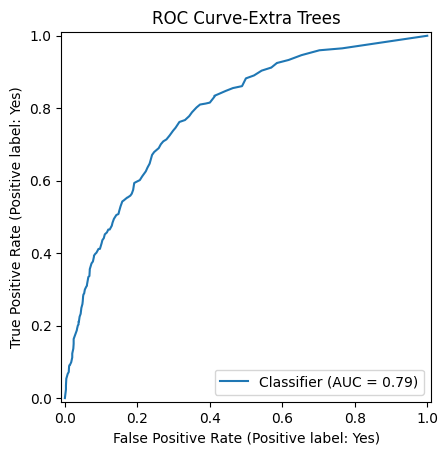


Model:XGBoost

Accuracy: 0.7785663591199432

 Classification Report :
               precision    recall  f1-score   support

          No       0.83      0.87      0.85      1035
         Yes       0.60      0.51      0.55       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409


 Confusion Matrix :
 [[905 130]
 [182 192]]

 ROC Score : 0.8215311684621148


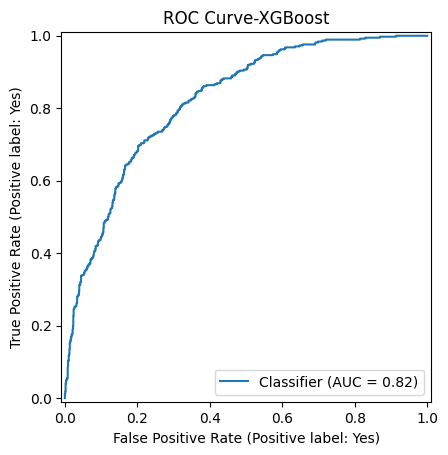


Model:SGD Classifier

Accuracy: 0.7785663591199432

 Classification Report :
               precision    recall  f1-score   support

          No       0.86      0.84      0.85      1035
         Yes       0.58      0.61      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409


 Confusion Matrix :
 [[869 166]
 [146 228]]

 ROC Score : 0.8337647575499239


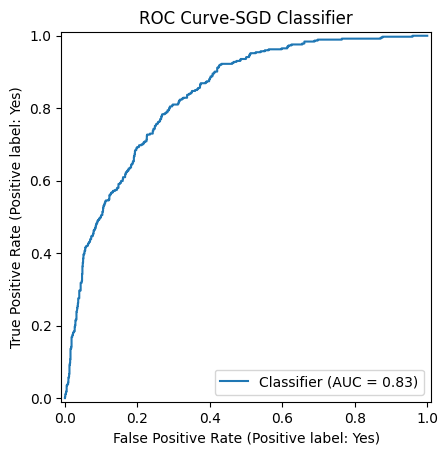


Model:SVM

Accuracy: 0.7913413768630234

 Classification Report :
               precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.64      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409


 Confusion Matrix :
 [[934 101]
 [193 181]]

 ROC Score : 0.7901754114030328


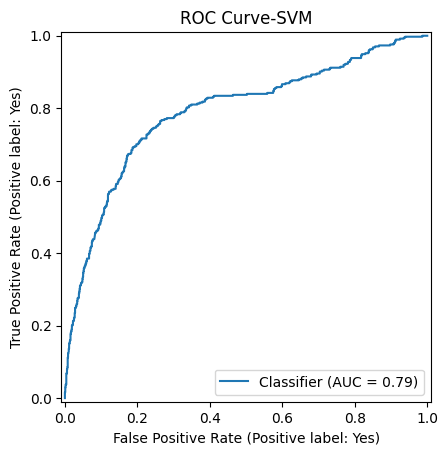


Model:KNN

Accuracy: 0.7636621717530163

 Classification Report :
               precision    recall  f1-score   support

          No       0.84      0.83      0.84      1035
         Yes       0.55      0.57      0.56       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.76      0.77      1409


 Confusion Matrix :
 [[861 174]
 [159 215]]

 ROC Score : 0.7896096515022346


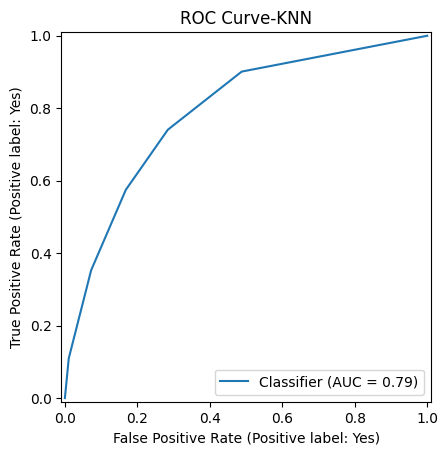


Model:Naive Bayes

Accuracy: 0.694819020581973

 Classification Report :
               precision    recall  f1-score   support

          No       0.92      0.64      0.76      1035
         Yes       0.46      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409


 Confusion Matrix :
 [[666 369]
 [ 61 313]]

 ROC Score : 0.8074297966881089


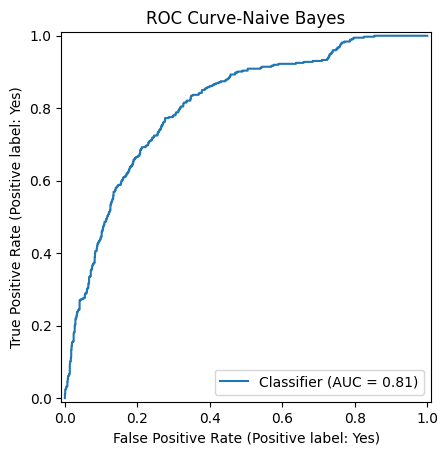

In [198]:
for name,model in models.items():
  print(f"\n{'='*50}")
  print(f"Model:{name}")
  print(f"\n{'='*50}")

  if name=='XGBoost':
    y_train_model=y_train.map({'No':0,'Yes':1})
  else:
    y_train_model=y_train

  if name=='Naive Bayes' and issparse(X_train_processed):
    X_train_model=X_train_processed.toarray()
    X_test_model=X_test_processed.toarray()
  else:
    X_train_model=X_train_processed
    X_test_model=X_test_processed
  model.fit(X_train_model,y_train_model)

  y_pred=model.predict(X_test_model)


  if name=="XGBoost":
    y_pred=pd.Series(y_pred,index=y_test.index).map({0:'No',1:'Yes'})


  accuracy=accuracy_score(y_test,y_pred)
  print("Accuracy:",accuracy)

  print("\n Classification Report :\n",classification_report(y_test,y_pred))

  print("\n Confusion Matrix :\n", confusion_matrix(y_test,y_pred))


  if hasattr(model,"predict_proba"):
    y_prob=model.predict_proba(X_test_model)[:,1]
  else:
    y_prob=model.decision_function(X_test_model)

  Roc_Score=roc_auc_score(y_test,y_prob)
  print("\n ROC Score :",Roc_Score)

  results[name]={'Accuracy':accuracy,
                 'Precision (Yes)':precision_score(y_test,y_pred,pos_label='Yes',zero_division=0),
                 'Recall(Yes)':recall_score(y_test,y_pred,pos_label='Yes',zero_division=0),
                 'F1_score(Yes)':f1_score(y_test,y_pred,pos_label='Yes',zero_division=0),
                 'ROC_AUC':Roc_Score
  }
  RocCurveDisplay.from_predictions(y_test,y_prob,pos_label='Yes')
  plt.title(f"ROC Curve-{name}")
  plt.show()


In [199]:
results_df=pd.DataFrame(results).T
print(results_df)

                          Accuracy  Precision (Yes)  Recall(Yes)  F1_score(Yes)   ROC_AUC
Logistic Regression       0.805536         0.657233     0.558824       0.604046  0.842135
Decision Tree Classifier  0.722498         0.478149     0.497326       0.487549  0.650353
Rndom Forest Classifier   0.787793         0.627986     0.491979       0.551724  0.816085
AdaBoost                  0.800568         0.643963     0.556150       0.596844  0.843166
Gradient Boosting         0.802697         0.665517     0.516043       0.581325  0.843405
Extra Trees               0.765791         0.570513     0.475936       0.518950  0.786268
XGBoost                   0.778566         0.596273     0.513369       0.551724  0.821531
SGD Classifier            0.778566         0.578680     0.609626       0.593750  0.833765
SVM                       0.791341         0.641844     0.483957       0.551829  0.790175
KNN                       0.763662         0.552699     0.574866       0.563565  0.789610
Naive Baye

In [200]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

results_df=pd.DataFrame(results).T
print(
    results_df.sort_values(
        by='F1_score(Yes)',
        ascending=False
    )
    .round(3)
    )



                          Accuracy  Precision (Yes)  Recall(Yes)  F1_score(Yes)  ROC_AUC
Logistic Regression          0.806            0.657        0.559          0.604    0.842
AdaBoost                     0.801            0.644        0.556          0.597    0.843
SGD Classifier               0.779            0.579        0.610          0.594    0.834
Naive Bayes                  0.695            0.459        0.837          0.593    0.807
Gradient Boosting            0.803            0.666        0.516          0.581    0.843
KNN                          0.764            0.553        0.575          0.564    0.790
SVM                          0.791            0.642        0.484          0.552    0.790
XGBoost                      0.779            0.596        0.513          0.552    0.822
Rndom Forest Classifier      0.788            0.628        0.492          0.552    0.816
Extra Trees                  0.766            0.571        0.476          0.519    0.786
Decision Tree Classif

# Phase 2:  Stratified K-Fold Cross-Validation

In [201]:
from sklearn.model_selection import StratifiedKFold,cross_val_score

skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [202]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

LR_Pipeline = Pipeline([('preprocessor',preprocessor),('classifier',LogisticRegression(max_iter=1000,random_state=42))])


In [203]:
cv_scores=cross_val_score(
    LR_Pipeline,
    X_train,
    y_train,cv=skf,
    scoring='accuracy'
)
print("Crosss-validation scores:",cv_scores)
print("Mean CV accuracy:",cv_scores.mean())

Crosss-validation scores: [0.79946761 0.78172138 0.80212955 0.81632653 0.81083481]
Mean CV accuracy: 0.802095977784117


In [204]:
models_cv = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(random_state=42),
    "Random Forest Classifier": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss'),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [205]:
from sklearn.preprocessing import FunctionTransformer
from scipy.sparse import issparse

In [206]:
cv_results={}

In [207]:
for name,model in models_cv.items():
  if name=='XGBoost':
    y_train_cv=y_train.map({'Yes':1,'No':0})
  else:
    y_train_cv=y_train

  if name=='Naive Bayes':
    pipeline=Pipeline([

                       ('preprocessor',preprocessor),
                        ('to_dense',FunctionTransformer(lambda x: x.toarray() if issparse(x) else x) ),
                       ('classifier',model)
    ]

    )

  else:
    pipeline= Pipeline(
        [
            ('preprocessor',preprocessor),
            ('classifier',model)
        ]

    )


  scores = cross_val_score(
      pipeline,
      X_train,
      y_train_cv,
      cv=skf,
      scoring='accuracy'
  )
  cv_results[name]=scores.mean()
  print(f"{name}:{scores.mean():.4f}")

Logistic Regression:0.8021
Decision Tree Classifier:0.7277
Random Forest Classifier:0.7845
AdaBoost:0.8000
Gradient Boosting:0.8033
XGBoost:0.7845
SVM:0.8035
KNN:0.7652
Naive Bayes:0.6967


In [208]:
print(cv_results)

{'Logistic Regression': np.float64(0.802095977784117), 'Decision Tree Classifier': np.float64(0.727725251812054), 'Random Forest Classifier': np.float64(0.7845251622928885), 'AdaBoost': np.float64(0.79996627270879), 'Gradient Boosting': np.float64(0.8033404202672652), 'XGBoost': np.float64(0.7845246894803949), 'SVM': np.float64(0.8035161489107188), 'KNN': np.float64(0.7651764142215693), 'Naive Bayes': np.float64(0.6966639926493418)}


In [209]:
list(cv_results.items())

[('Logistic Regression', np.float64(0.802095977784117)),
 ('Decision Tree Classifier', np.float64(0.727725251812054)),
 ('Random Forest Classifier', np.float64(0.7845251622928885)),
 ('AdaBoost', np.float64(0.79996627270879)),
 ('Gradient Boosting', np.float64(0.8033404202672652)),
 ('XGBoost', np.float64(0.7845246894803949)),
 ('SVM', np.float64(0.8035161489107188)),
 ('KNN', np.float64(0.7651764142215693)),
 ('Naive Bayes', np.float64(0.6966639926493418))]

In [210]:
cv_results_df = pd.DataFrame(list(cv_results.items()),columns=['Model', 'Mean_CV_Accuracy'])


In [211]:
print(cv_results_df)

                      Model  Mean_CV_Accuracy
0       Logistic Regression          0.802096
1  Decision Tree Classifier          0.727725
2  Random Forest Classifier          0.784525
3                  AdaBoost          0.799966
4         Gradient Boosting          0.803340
5                   XGBoost          0.784525
6                       SVM          0.803516
7                       KNN          0.765176
8               Naive Bayes          0.696664


In [212]:
print(cv_results_df.sort_values(by='Mean_CV_Accuracy',ascending=False).round(4))

                      Model  Mean_CV_Accuracy
6                       SVM            0.8035
4         Gradient Boosting            0.8033
0       Logistic Regression            0.8021
3                  AdaBoost            0.8000
2  Random Forest Classifier            0.7845
5                   XGBoost            0.7845
7                       KNN            0.7652
1  Decision Tree Classifier            0.7277
8               Naive Bayes            0.6967


# Cross validation with multiple evaluation metrics

In [213]:
from sklearn.model_selection import cross_validate

In [214]:
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, pos_label='Yes', zero_division=0),
    'recall': make_scorer(recall_score, pos_label='Yes', zero_division=0),
    'f1': make_scorer(f1_score, pos_label='Yes', zero_division=0),
    'roc_auc': 'roc_auc'
}

In [215]:
scores=cross_validate(
    pipeline,
    X_train,
    y_train_cv,
    cv=skf,
    scoring=scoring

)

In [216]:
cv_results[name] = {
    'Accuracy': scores['test_accuracy'].mean(),
    'Precision': scores['test_precision'].mean(),
    'Recall': scores['test_recall'].mean(),
    'F1-score': scores['test_f1'].mean(),
    'ROC-AUC': scores['test_roc_auc'].mean()
}

In [217]:

cv_results_df = pd.DataFrame(cv_results).T

print(cv_results_df.sort_values(
    by='F1-score',
    ascending=False
).round(4))


                          Accuracy  Precision  Recall  F1-score  ROC-AUC
SVM                         0.8035     0.8035  0.8035    0.8035   0.8035
Gradient Boosting           0.8033     0.8033  0.8033    0.8033   0.8033
Logistic Regression         0.8021     0.8021  0.8021    0.8021   0.8021
AdaBoost                    0.8000     0.8000  0.8000    0.8000   0.8000
Random Forest Classifier    0.7845     0.7845  0.7845    0.7845   0.7845
XGBoost                     0.7845     0.7845  0.7845    0.7845   0.7845
KNN                         0.7652     0.7652  0.7652    0.7652   0.7652
Decision Tree Classifier    0.7277     0.7277  0.7277    0.7277   0.7277
Naive Bayes                 0.6967     0.4612  0.8482    0.5974   0.8212


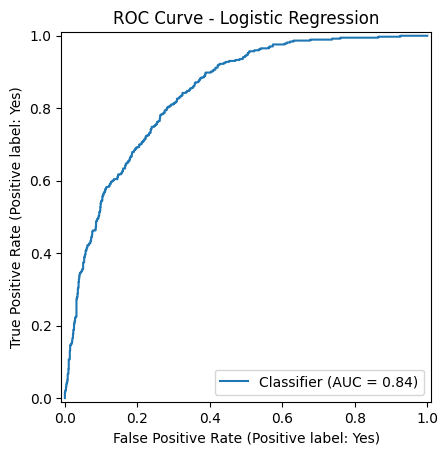

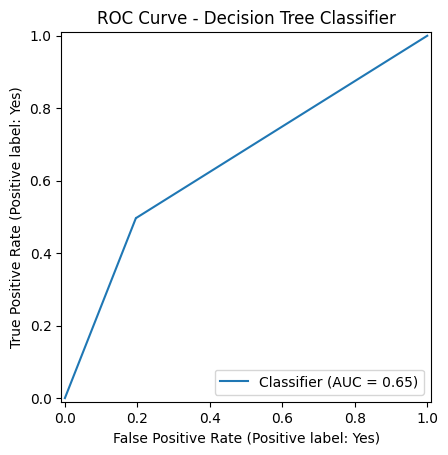

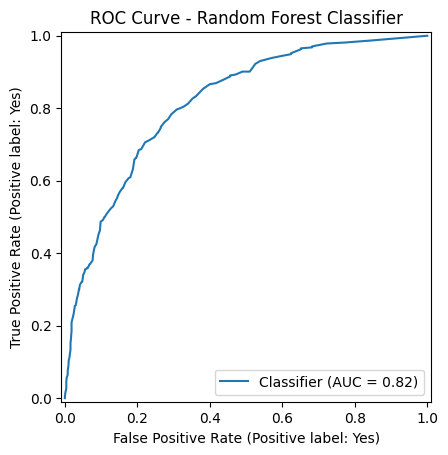

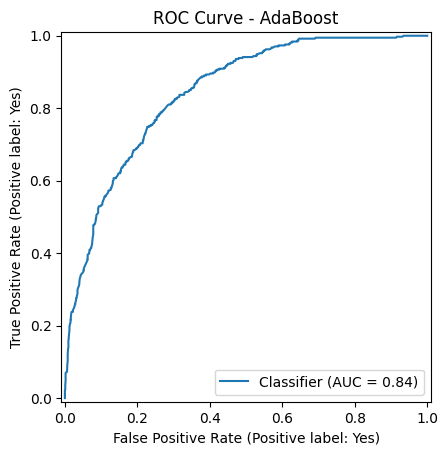

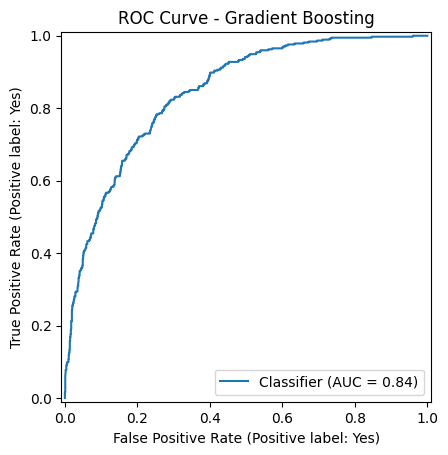

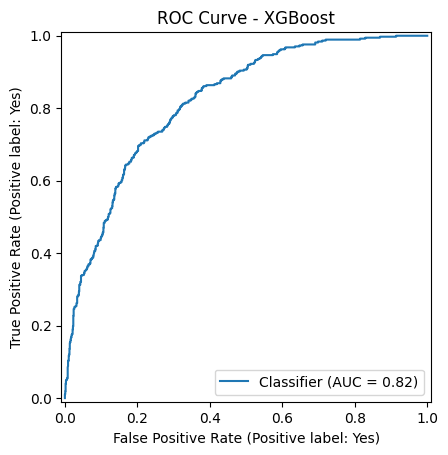

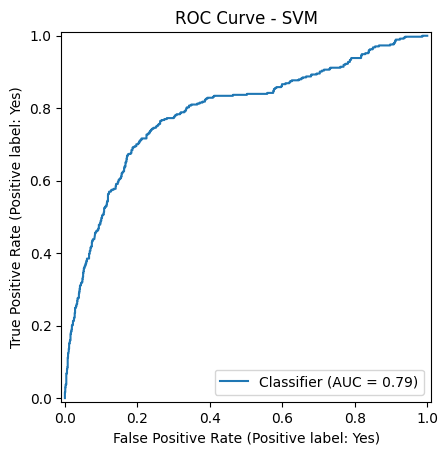

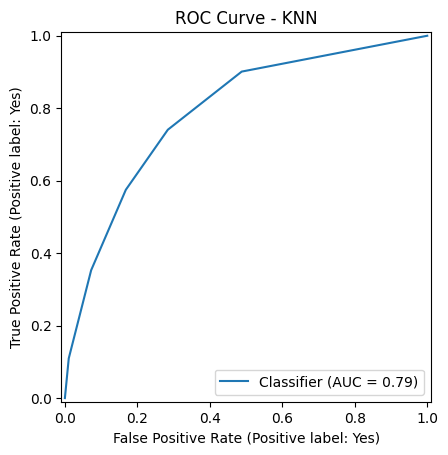

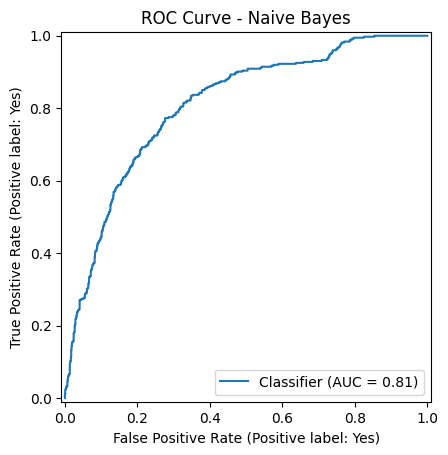

In [218]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

for name, model in models_cv.items():

    if name == 'XGBoost':
        y_train_cv = y_train.map({'No': 0, 'Yes': 1})
    else:
        y_train_cv = y_train

    if name == 'Naive Bayes':
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('to_dense', FunctionTransformer(
                lambda x: x.toarray() if issparse(x) else x
            )),
            ('classifier', model)
        ])
    else:
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', model)
        ])

    pipeline.fit(X_train, y_train_cv)

    if name == 'XGBoost':
        y_prob = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_prob = pipeline.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        pos_label='Yes'
    )

    plt.title(f'ROC Curve - {name}')
    plt.show()

# Hyperparameter Tuning

## Logistic Regression

In [219]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

In [220]:
f1_yes = make_scorer(
    f1_score,
    pos_label='Yes',
    zero_division=0
)

In [221]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

In [222]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs'],
    'classifier__penalty': ['l2'],
    'classifier__max_iter': [500, 1000]
}

### GridSearchCV

In [223]:
from sklearn.model_selection import GridSearchCV

In [224]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=1,
    verbose=2,
    error_score='raise'
)

In [225]:
grid_search.fit(X_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=lbfgs; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=lbfgs; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=

GridSearchCV(cv=5, error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('categorical',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['gender',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'PhoneService',
                                                                          'MultipleLines',
                                                                          'InternetService',
                                                                          'OnlineSecurity',
                                                                          'OnlineBackup',
                                                                          'DeviceProtection',
                                                                          'TechSupport',
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Cont...
                                                                          'MonthlyCharges',
                                                                          'TotalCharges'])])),
                                       ('classifier',
                                        LogisticRegression(random_state=42))]),
             n_jobs=1,
             param_grid={'classifier__C': [0.01, 0.1, 1, 10, 100],
                         'classifier__max_iter': [500, 1000],
                         'classifier__penalty': ['l2'],
                         'classifier__solver': ['liblinear', 'lbfgs']},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes, zero_division=0),
             verbose=2)

In [226]:
print("Best Parameters:",grid_search.best_params_)
print("Best CV F1 Score:",grid_search.best_score_)

Best Parameters: {'classifier__C': 100, 'classifier__max_iter': 500, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Best CV F1 Score: 0.599371387712228


In [227]:
#Evaluate the best model on the test dataset

from sklearn.metrics import classification_report, confusion_matrix

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.65      0.55      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409

[[923 112]
 [168 206]]


### RandomizedSearchCV

In [228]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring=f1_yes,
    random_state=42,
    n_jobs=1,
    verbose=2,
    error_score='raise'
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=0.01, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=liblinear; total time=   0.1s
[CV] END classifier__C=100, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=lbfgs; total time=   0.1s
[CV] END classifier__C=100, classifier__max_iter=500, classifier__penalty=l2, classifier__solver=lbfgs; total time=   0.1s
[CV] END classifier__C=100, classifier__max_iter=500,

RandomizedSearchCV(cv=5, error_score='raise',
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('categorical',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               ['gender',
                                                                                'Partner',
                                                                                'Dependents',
                                                                                'PhoneService',
                                                                                'MultipleLines',
                                                                                'InternetService',
                                                                                'OnlineSecurity',
                                                                                'OnlineBackup',
                                                                                'DeviceProtection',
                                                                                'TechSupport',
                                                                                'StreamingTV',
                                                                                'StreamingMovies'...
                                                                                'TotalCharges'])])),
                                             ('classifier',
                                              LogisticRegression(random_state=42))]),
                   n_jobs=1,
                   param_distributions={'classifier__C': [0.01, 0.1, 1, 10,
                                                          100],
                                        'classifier__max_iter': [500, 1000],
                                        'classifier__penalty': ['l2'],
                                        'classifier__solver': ['liblinear',
                                                               'lbfgs']},
                   random_state=42,
                   scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes, zero_division=0),
                   verbose=2)

In [229]:
print("Best Parameters:", random_search.best_params_)
print("Best CV F1 Score:", random_search.best_score_)

Best Parameters: {'classifier__solver': 'liblinear', 'classifier__penalty': 'l2', 'classifier__max_iter': 1000, 'classifier__C': 100}
Best CV F1 Score: 0.599371387712228


In [230]:
best_random_model = random_search.best_estimator_

In [231]:
y_pred_random = best_random_model.predict(X_test)

In [232]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_random))
print(confusion_matrix(y_test, y_pred_random))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.65      0.55      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409

[[923 112]
 [168 206]]


In [233]:


comparison = pd.DataFrame({
    'Method': ['GridSearchCV', 'RandomizedSearchCV'],
    'Best CV F1 Score': [
        grid_search.best_score_,
        random_search.best_score_
    ],
    'Test F1 Score': [
        f1_score(y_test, y_pred, pos_label='Yes'),
        f1_score(y_test, y_pred_random, pos_label='Yes')
    ]
})

print(comparison)

               Method  Best CV F1 Score  Test F1 Score
0        GridSearchCV          0.599371       0.595376
1  RandomizedSearchCV          0.599371       0.595376


# **Feature Selection**

## Recursive Feature Elimination - RFE

In [234]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

In [235]:
rfe= RFE(
    estimator=LogisticRegression(max_iter=1000),
    n_features_to_select=20,
    step=1
)

In [236]:
pipeline_rfe=Pipeline([
    ('preprocessor',preprocessor),#Encoding and scaling
    ('feature_selection',rfe), #Select 20 features
    ('classifier',LogisticRegression(max_iter=1000)) # Final Model
])

In [237]:
pipeline_rfe.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('numerical', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('feature_selection',
                 RFE(estimator=LogisticRegression(max_iter=1000),
                     n_features_to_select=20)),
                ('classifier', LogisticRegression(max_iter=1000))])

In [238]:
y_pred_rfe=pipeline_rfe.predict(X_test)

In [239]:
print(classification_report(y_test, y_pred_rfe))
print(confusion_matrix(y_test, y_pred_rfe))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.56      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

[[917 118]
 [166 208]]


In [269]:
y_prob_rfe = pipeline_rfe.predict_proba(X_test)[:, 1]

In [270]:
from sklearn.metrics import roc_auc_score

roc_rfe = roc_auc_score(
    y_test,
    y_prob_rfe,
    labels=['No', 'Yes']
)

print("RFE ROC-AUC:", roc_rfe)

RFE ROC-AUC: 0.841304347826087


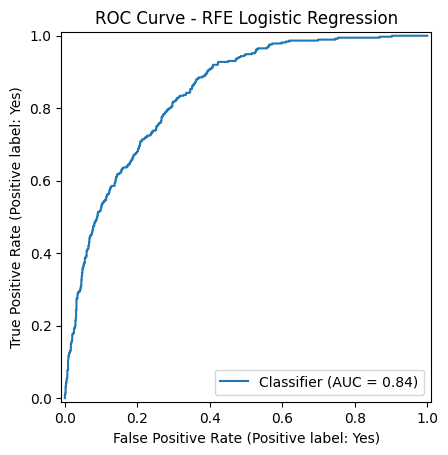

In [271]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rfe,
    pos_label='Yes'
)

plt.title('ROC Curve - RFE Logistic Regression')
plt.show()

In [240]:
#Get all transformed feature names

feature_names=pipeline_rfe.named_steps[   #Access the preprocessing step,
    'preprocessor'
    ].get_feature_names_out()# retrieve the names of its output features, and store those names in feature_names.

#print(feature_names)

In [241]:
#Get the Boolean selection mask from RFE

support = pipeline_rfe.named_steps[
    'feature_selection'
].support_

In [242]:
#Extract only the selected feature names
selected_features = feature_names[support]
print("Number of selected features:", len(selected_features))
print("\nSelected Features:\n",selected_features)

Number of selected features: 20

Selected Features:
 ['categorical__MultipleLines_No' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes'
 'categorical__OnlineBackup_No internet service'
 'categorical__DeviceProtection_No internet service'
 'categorical__TechSupport_No internet service'
 'categorical__StreamingTV_No'
 'categorical__StreamingTV_No internet service'
 'categorical__StreamingMovies_No'
 'categorical__StreamingMovies_No internet service'
 'categorical__Contract_Month-to-month' 'categorical__Contract_Two year'
 'categorical__PaperlessBilling_No'
 'categorical__PaymentMethod_Electronic check' 'numerical__tenure'
 'numerical__MonthlyCharges' 'numerical__TotalCharges']


In [243]:
rfe_ranking = pipeline_rfe.named_steps['feature_selection'].ranking_

print(rfe_ranking)

[ 6  7  9 10 23  3  4 12  1 11 20  1  1  1 13  1  1 24  1 19 21  1 26 15
  1  2  1  1  8  1  1  5  1 14  1  1 25 17 16  1 18 22  1  1  1]


# **PCA (Principal Component Analysis)**

In [244]:
from sklearn.decomposition import PCA

In [245]:
X_train_preprocessed=preprocessor.fit_transform(X_train)

In [246]:
print(X_train_preprocessed.shape)

(5634, 45)


In [247]:
print(type(X_train_preprocessed))

<class 'numpy.ndarray'>


In [248]:
pca=PCA(n_components=20)

In [249]:
X_train_pca_transformed=pca.fit_transform(X_train_preprocessed)

In [250]:
print(X_train_pca_transformed.shape)

(5634, 20)


In [251]:
explained_variance=pca.explained_variance_ratio_
print(explained_variance)

[0.27320009 0.17971525 0.08118954 0.06068723 0.04477935 0.04024936
 0.03572397 0.03358491 0.02865071 0.0251068  0.02401389 0.02197053
 0.02063968 0.01852987 0.01789082 0.01765092 0.01750016 0.01664321
 0.01458678 0.0131211 ]


In [252]:
cumulative_variance=np.cumsum(explained_variance)
print(cumulative_variance)

[0.27320009 0.45291534 0.53410489 0.59479212 0.63957147 0.67982084
 0.71554481 0.74912972 0.77778043 0.80288723 0.82690111 0.84887165
 0.86951133 0.8880412  0.90593202 0.92358294 0.9410831  0.95772631
 0.97231308 0.98543418]


In [253]:
# the number of components needed for 95% variance

n_components_95 = np.argmax(
    cumulative_variance>=0.95

 )+1

print("Number of componenets required:", n_components_95)

Number of componenets required: 18


In [254]:
X_train_pca_18=X_train_pca_transformed[:,:18]

print(X_train_pca_18.shape)

(5634, 18)


In [255]:
X_test_processed=preprocessor.transform(X_test)

In [256]:
X_test_pca_transformed = pca.transform(X_test_processed)

In [257]:
X_test_pca_18=X_test_pca_transformed[:,:18]
print(X_test_pca_18.shape)

(1409, 18)


# Train Logistic Regression using PCA data

In [258]:
lr_pca=LogisticRegression(max_iter=1000,random_state=2)

lr_pca.fit(X_train_pca_18,y_train)

LogisticRegression(max_iter=1000, random_state=2)

In [259]:
y_pred_pca= lr_pca.predict(X_test_pca_18)

In [260]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_pca))

              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.64      0.52      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [261]:
from sklearn.metrics import confusion_matrix

cm_pca = confusion_matrix(y_test, y_pred_pca)

print(cm_pca)

[[928 107]
 [180 194]]


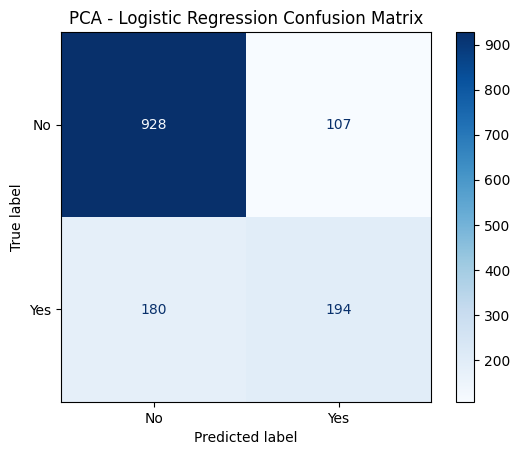

In [262]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm_pca,
    display_labels=['No', 'Yes']
).plot(cmap='Blues')

plt.title('PCA - Logistic Regression Confusion Matrix')
plt.show()

In [263]:
from sklearn.metrics import roc_auc_score

y_prob_pca = lr_pca.predict_proba(X_test_pca_18)[:, 1]

roc_pca = roc_auc_score(
    y_test,
    y_prob_pca,
    labels=['No', 'Yes']
)

print("PCA ROC-AUC Score:", roc_pca)

PCA ROC-AUC Score: 0.834968611950709


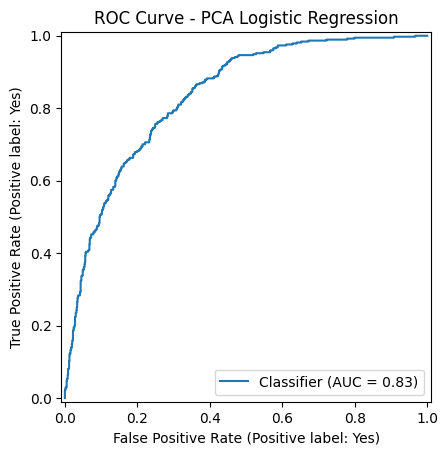

In [264]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_pca,
    pos_label='Yes'
)

plt.title('ROC Curve - PCA Logistic Regression')
plt.show()

In [265]:
%whos

Variable                     Type                  Data/Info
------------------------------------------------------------
AdaBoostClassifier           ABCMeta               <class 'sklearn.ensemble.<...>ting.AdaBoostClassifier'>
ColumnTransformer            ABCMeta               <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay       type                  <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier       ABCMeta               <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
ExtraTreesClassifier         ABCMeta               <class 'sklearn.ensemble.<...>st.ExtraTreesClassifier'>
FunctionTransformer          type                  <class 'sklearn.preproces<...>mer.FunctionTransformer'>
GaussianNB                   ABCMeta               <class 'sklearn.naive_bayes.GaussianNB'>
GradientBoostingClassifier   ABCMeta               <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
GridSearchCV                 ABCMeta 

In [266]:
print(results_df)

                          Accuracy  Precision (Yes)  Recall(Yes)  F1_score(Yes)   ROC_AUC
Logistic Regression       0.805536         0.657233     0.558824       0.604046  0.842135
Decision Tree Classifier  0.722498         0.478149     0.497326       0.487549  0.650353
Rndom Forest Classifier   0.787793         0.627986     0.491979       0.551724  0.816085
AdaBoost                  0.800568         0.643963     0.556150       0.596844  0.843166
Gradient Boosting         0.802697         0.665517     0.516043       0.581325  0.843405
Extra Trees               0.765791         0.570513     0.475936       0.518950  0.786268
XGBoost                   0.778566         0.596273     0.513369       0.551724  0.821531
SGD Classifier            0.778566         0.578680     0.609626       0.593750  0.833765
SVM                       0.791341         0.641844     0.483957       0.551829  0.790175
KNN                       0.763662         0.552699     0.574866       0.563565  0.789610
Naive Baye

In [268]:
print(results_df.head())
print(results_df.columns)

                          Accuracy  Precision (Yes)  Recall(Yes)  F1_score(Yes)   ROC_AUC
Logistic Regression       0.805536         0.657233     0.558824       0.604046  0.842135
Decision Tree Classifier  0.722498         0.478149     0.497326       0.487549  0.650353
Rndom Forest Classifier   0.787793         0.627986     0.491979       0.551724  0.816085
AdaBoost                  0.800568         0.643963     0.556150       0.596844  0.843166
Gradient Boosting         0.802697         0.665517     0.516043       0.581325  0.843405
Index(['Accuracy', 'Precision (Yes)', 'Recall(Yes)', 'F1_score(Yes)', 'ROC_AUC'], dtype='object')


In [273]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# RFE metrics
results_df.loc['Logistic Regression + RFE'] = [
    accuracy_score(y_test, y_pred_rfe),
    precision_score(y_test, y_pred_rfe, pos_label='Yes'),
    recall_score(y_test, y_pred_rfe, pos_label='Yes'),
    f1_score(y_test, y_pred_rfe, pos_label='Yes'),
    roc_auc_score(y_test, y_prob_rfe)
]

# PCA metrics
results_df.loc['Logistic Regression + PCA'] = [
    accuracy_score(y_test, y_pred_pca),
    precision_score(y_test, y_pred_pca, pos_label='Yes'),
    recall_score(y_test, y_pred_pca, pos_label='Yes'),
    f1_score(y_test, y_pred_pca, pos_label='Yes'),
    roc_auc_score(y_test, y_prob_pca)
]

In [274]:
print(results_df)

                           Accuracy  Precision (Yes)  Recall(Yes)  F1_score(Yes)   ROC_AUC
Logistic Regression        0.805536         0.657233     0.558824       0.604046  0.842135
Decision Tree Classifier   0.722498         0.478149     0.497326       0.487549  0.650353
Rndom Forest Classifier    0.787793         0.627986     0.491979       0.551724  0.816085
AdaBoost                   0.800568         0.643963     0.556150       0.596844  0.843166
Gradient Boosting          0.802697         0.665517     0.516043       0.581325  0.843405
Extra Trees                0.765791         0.570513     0.475936       0.518950  0.786268
XGBoost                    0.778566         0.596273     0.513369       0.551724  0.821531
SGD Classifier             0.778566         0.578680     0.609626       0.593750  0.833765
SVM                        0.791341         0.641844     0.483957       0.551829  0.790175
KNN                        0.763662         0.552699     0.574866       0.563565  0.789610

# SMOTE (Synthetic Minority Over-sampling Technique)

## (SMOTE for Nominal and Continuous features).

In [275]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nClass distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

Before SMOTE:
Churn
No     4139
Yes    1495
Name: count, dtype: int64

Class distribution (%):
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64


In [278]:
from imblearn.over_sampling import SMOTENC

In [280]:
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

print(categorical_indices)

[0, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


In [281]:
smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_smote, y_train_smote = smote_nc.fit_resample(
    X_train, y_train
)

In [282]:
print("After SMOTE:")
print(y_train_smote.value_counts())

print("\nClass distribution (%):")
print(y_train_smote.value_counts(normalize=True) * 100)

After SMOTE:
Churn
No     4139
Yes    4139
Name: count, dtype: int64

Class distribution (%):
Churn
No     50.0
Yes    50.0
Name: proportion, dtype: float64


In [283]:
X_train_smote_processed = preprocessor.fit_transform(X_train_smote)

X_test_processed = preprocessor.transform(X_test)

In [284]:
print("Training shape:", X_train_smote_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (8278, 45)
Testing shape: (1409, 45)


In [285]:
lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_smote.fit(X_train_smote_processed, y_train_smote)

LogisticRegression(max_iter=1000, random_state=42)

In [286]:
y_pred_smote = lr_smote.predict(X_test_processed)

In [287]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

          No       0.88      0.75      0.81      1035
         Yes       0.52      0.72      0.60       374

    accuracy                           0.75      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.79      0.75      0.76      1409



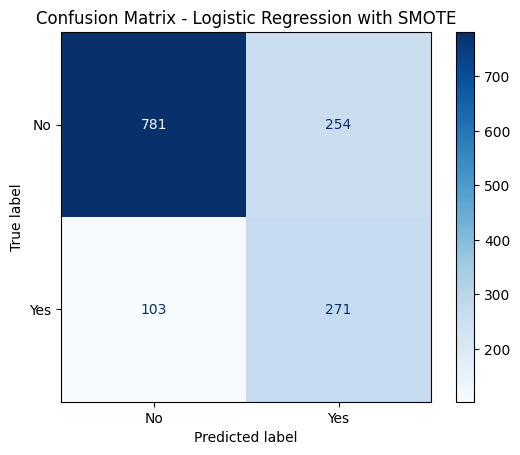

In [288]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_smote = confusion_matrix(y_test, y_pred_smote)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression with SMOTE')
plt.show()

In [289]:
y_prob_smote = lr_smote.predict_proba(X_test_processed)[:, 1]

In [290]:
from sklearn.metrics import roc_auc_score

roc_smote = roc_auc_score(y_test, y_prob_smote)

print("ROC-AUC Score:", roc_smote)

ROC-AUC Score: 0.8209744503862152


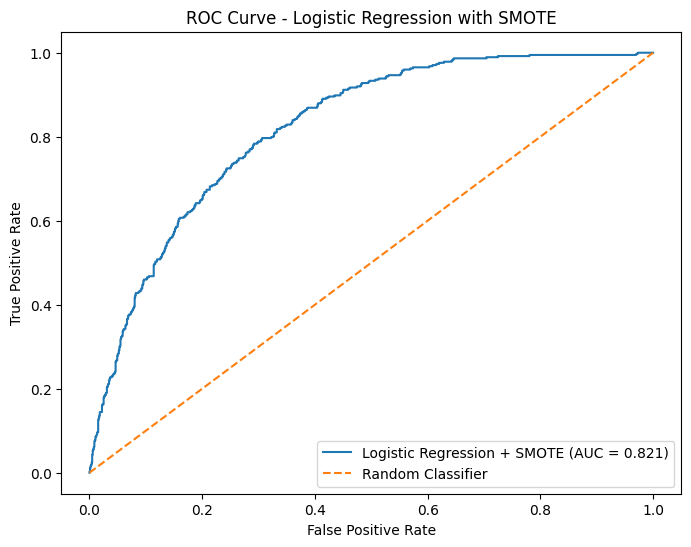

In [291]:
from sklearn.metrics import roc_curve

fpr_smote, tpr_smote, thresholds_smote = roc_curve(
    y_test,
    y_prob_smote,
    pos_label='Yes'
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_smote,
    tpr_smote,
    label=f'Logistic Regression + SMOTE (AUC = {roc_smote:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression with SMOTE')
plt.legend()
plt.show()

In [293]:
results_df.loc['Logistic Regression + SMOTE'] = [
    accuracy_score(y_test, y_pred_smote),
    precision_score(y_test, y_pred_smote, pos_label='Yes'),
    recall_score(y_test, y_pred_smote, pos_label='Yes'),
    f1_score(y_test, y_pred_smote, pos_label='Yes'),
    roc_auc_score(y_test, y_prob_smote)
]

print(results_df.round(4))

                             Accuracy  Precision (Yes)  Recall(Yes)  F1_score(Yes)  ROC_AUC
Logistic Regression            0.8055           0.6572       0.5588         0.6040   0.8421
Decision Tree Classifier       0.7225           0.4781       0.4973         0.4875   0.6504
Rndom Forest Classifier        0.7878           0.6280       0.4920         0.5517   0.8161
AdaBoost                       0.8006           0.6440       0.5561         0.5968   0.8432
Gradient Boosting              0.8027           0.6655       0.5160         0.5813   0.8434
Extra Trees                    0.7658           0.5705       0.4759         0.5190   0.7863
XGBoost                        0.7786           0.5963       0.5134         0.5517   0.8215
SGD Classifier                 0.7786           0.5787       0.6096         0.5938   0.8338
SVM                            0.7913           0.6418       0.4840         0.5518   0.7902
KNN                            0.7637           0.5527       0.5749         0.56